<a href="https://colab.research.google.com/github/lizlady-dev/lizlady-dev/blob/index.html/PRODUCCIONDETRUCHAS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install optuna statsmodels scikit-learn pandas numpy matplotlib seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import optuna

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")

optuna.logging.set_verbosity(optuna.logging.WARNING)



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [ ]:
df = pd.read_csv("truchas.csv", sep=";")

df.head()

,anios,produccion
0,2000,662.48
1,2001,1060.06
2,2002,1191.30
3,2003,1290.30
4,2004,1997.12


In [ ]:
# @title
# Reconstruir la serie temporal con índice anual reconocido

df = df.sort_values("anios").reset_index(drop=True)

# Crear fechas anuales
fechas = pd.to_datetime(
    df["anios"].astype(str) + "-01-01"
)

# Crear serie temporal
serie = pd.Series(
    df["produccion"].values,
    index=fechas,
    name="produccion"
)

# Establecer frecuencia anual
serie = serie.asfreq("YS")

print(serie)
print("\nFrecuencia:", serie.index.freq)

anios
2000-01-01      662.48
2001-01-01     1060.06
2002-01-01     1191.30
2003-01-01     1290.30
2004-01-01     1997.12
2005-01-01     2243.33
2006-01-01     2981.79
2007-01-01     3893.25
2008-01-01     8877.17
2009-01-01     9437.84
2010-01-01     9682.82
2011-01-01    15549.64
2012-01-01    18471.02
2013-01-01    29090.66
2014-01-01    28236.12
2015-01-01    34114.00
2016-01-01    43290.02
2017-01-01    45232.73
2018-01-01    50914.45
2019-01-01    32549.21
2020-01-01    33962.19
2021-01-01    32673.93
2022-01-01    41645.61
2023-01-01    22449.99
Freq: YS-JAN, Name: produccion, dtype: float64

Frecuencia: <YearBegin: month=1>


In [ ]:
print("ESTADÍSTICAS DESCRIPTIVAS")

print(serie.describe())

print("\nValores faltantes:")
print(serie.isnull().sum())

print("\nPrimer año:", serie.index.min())
print("Último año:", serie.index.max())
print("Cantidad de observaciones:", len(serie))

ESTADÍSTICAS DESCRIPTIVAS
count       24.000000
mean     19645.709583
std      16756.399409
min        662.480000
25%       2797.175000
50%      17010.330000
75%      32995.995000
max      50914.450000
Name: produccion, dtype: float64

Valores faltantes:
0

Primer año: 2000-01-01 00:00:00
Último año: 2023-01-01 00:00:00
Cantidad de observaciones: 24


Evolucion de la produccion


> vemos que la produccion muestra una tendencia general creciente, tambien se observa que en 2019 disminuye significativamente, y la produccion del 2023 respecto a 2022 disminuye considerablemente.



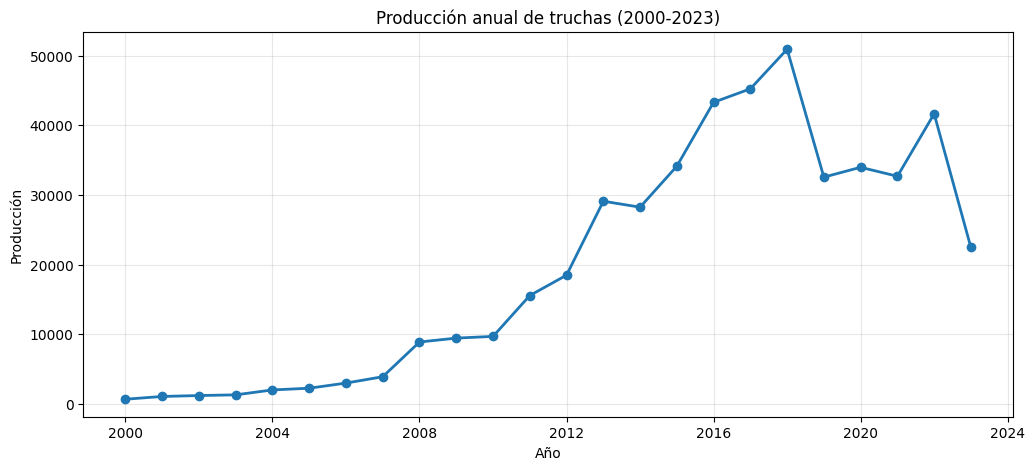

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    serie.index,
    serie.values,
    marker="o",
    linewidth=2
)

plt.title("Producción anual de truchas (2000-2023)")
plt.xlabel("Año")
plt.ylabel("Producción")
plt.grid(True, alpha=0.3)

plt.show()

distribución de la producción

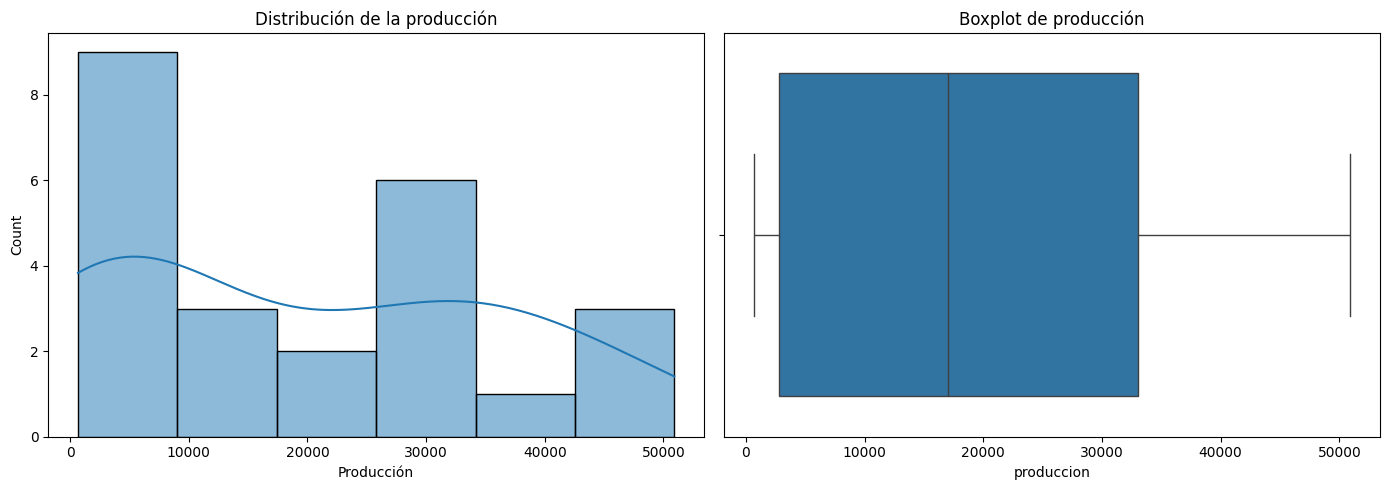

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    serie,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribución de la producción")
axes[0].set_xlabel("Producción")

sns.boxplot(
    x=serie,
    ax=axes[1]
)

axes[1].set_title("Boxplot de producción")

plt.tight_layout()
plt.show()

variacion porcentual

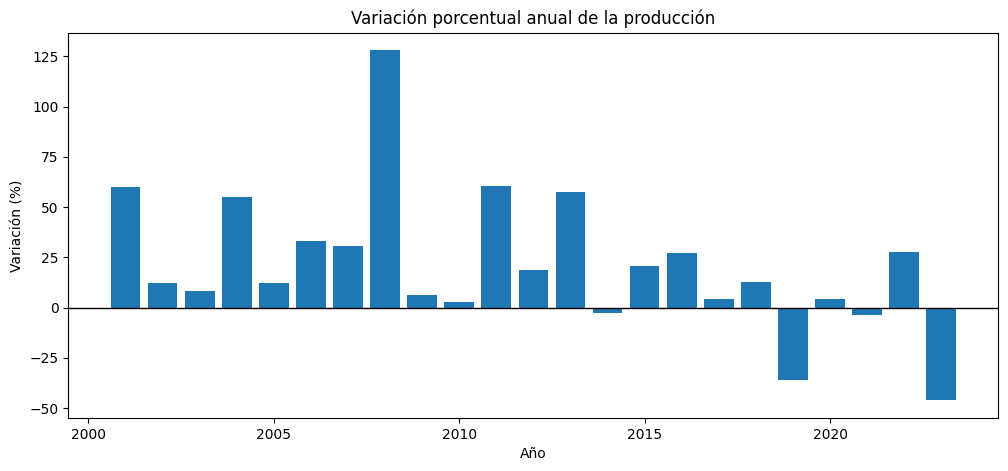

In [ ]:
variacion = serie.pct_change() * 100

plt.figure(figsize=(12, 5))

plt.bar(
    variacion.index,
    variacion.values
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Variación porcentual anual de la producción")
plt.xlabel("Año")
plt.ylabel("Variación (%)")

plt.show()

tendencia y media movil

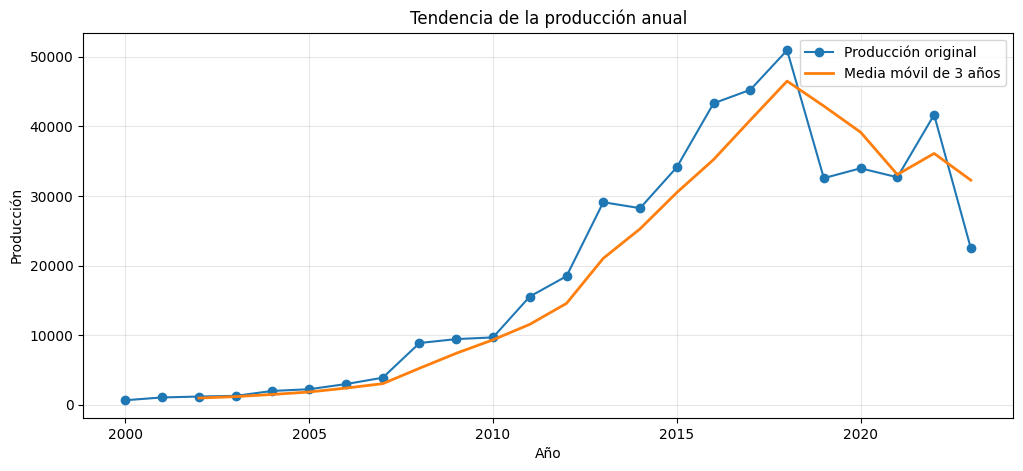

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    serie.index,
    serie,
    label="Producción original",
    marker="o"
)

plt.plot(
    serie.index,
    serie.rolling(3).mean(),
    label="Media móvil de 3 años",
    linewidth=2
)

plt.title("Tendencia de la producción anual")
plt.xlabel("Año")
plt.ylabel("Producción")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

MAE: error absoluto medio.
RMSE: raíz del error cuadrático medio.
MAPE: error porcentual absoluto medio.
# mientras menos sean los valores mejor sera el modelo

In [ ]:
from statsmodels.tsa.stattools import adfuller
resultado = adfuller(df["produccion"])
# Interpretar los resultados principales
estadistico_adf = resultado[0]
valor_p = resultado[1]
valores_criticos = resultado[4]

print(f"Estadístico ADF: {estadistico_adf}")
print(f"Valor p: {valor_p}")
print("Valores críticos:")
for nivel, valor in valores_criticos.items():
  print(f"   {nivel}: {valor}")

Estadístico ADF: -4.833103594428105
Valor p: 4.698670311727524e-05
Valores críticos:
   1%: -3.859073285322359
   5%: -3.0420456927297668
   10%: -2.6609064197530863


In [ ]:
def calcular_metricas(real, predicho):

    mae = mean_absolute_error(real, predicho)

    rmse = np.sqrt(
        mean_squared_error(real, predicho)
    )

    mape = mean_absolute_percentage_error(
        real, predicho
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    }

validacion cruzada temporal, se utilizara ya que se trabajan con datos anuales.

In [ ]:
tscv = TimeSeriesSplit(
    n_splits=5,
    test_size=2
)

for train_idx, test_idx in tscv.split(serie):

    train = serie.iloc[train_idx]
    test = serie.iloc[test_idx]

    print(
        f"Entrenamiento: {train.index.min()} - {train.index.max()} | "
        f"Prueba: {test.index.min()} - {test.index.max()}"
    )

Entrenamiento: 2000 - 2013 | Prueba: 2014 - 2015
Entrenamiento: 2000 - 2015 | Prueba: 2016 - 2017
Entrenamiento: 2000 - 2017 | Prueba: 2018 - 2019
Entrenamiento: 2000 - 2019 | Prueba: 2020 - 2021
Entrenamiento: 2000 - 2021 | Prueba: 2022 - 2023


In [ ]:
def evaluar_modelo(nombre, funcion_modelo):

    errores = []

    for train_idx, test_idx in tscv.split(serie):

        train = serie.iloc[train_idx].copy()
        test = serie.iloc[test_idx].copy()

        # Restaurar frecuencia anual
        train.index = pd.date_range(
            start=train.index[0],
            periods=len(train),
            freq="YS"
        )

        pred = funcion_modelo(
            train,
            len(test)
        )

        pred = np.asarray(pred)

        metricas = calcular_metricas(
            test.values,
            pred
        )

        errores.append(metricas)

    return {
        "Modelo": nombre,
        "MAE": np.mean([e["MAE"] for e in errores]),
        "RMSE": np.mean([e["RMSE"] for e in errores]),
        "MAPE": np.mean([e["MAPE"] for e in errores])
    }

In [ ]:
def modelo_naive(train, horizonte):

    return np.repeat(
        train.iloc[-1],
        horizonte
    )

In [ ]:
def modelo_drift(train, horizonte):

    pendiente = (
        train.iloc[-1] - train.iloc[0]
    ) / (len(train) - 1)

    return [
        train.iloc[-1] + pendiente * h
        for h in range(1, horizonte + 1)
    ]

In [ ]:
def modelo_holt(train, horizonte):

    modelo = ExponentialSmoothing(
        train,
        trend="add",
        damped_trend=True,
        seasonal=None
    )

    ajuste = modelo.fit(
        optimized=True
    )

    return ajuste.forecast(horizonte)

In [ ]:
def modelo_ets(train, horizonte):

    modelo = ExponentialSmoothing(
        train,
        trend="add",
        seasonal=None,
        initialization_method="estimated"
    )

    ajuste = modelo.fit(
        optimized=True
    )

    return ajuste.forecast(horizonte)

In [ ]:
def crear_modelo_arima(order):

    def funcion(train, horizonte):

        modelo = ARIMA(
            train,
            order=order
        )

        ajuste = modelo.fit()

        return ajuste.forecast(horizonte)

    return funcion

In [ ]:
resultados = []

modelos = {
    "Naive": modelo_naive,
    "Drift": modelo_drift,
    "Holt": modelo_holt,
    "ETS": modelo_ets,
    "ARIMA(1,1,0)": crear_modelo_arima((1,1,0)),
    "ARIMA(0,1,1)": crear_modelo_arima((0,1,1)),
    "ARIMA(1,1,1)": crear_modelo_arima((1,1,1)),
    "ARIMA(2,1,1)": crear_modelo_arima((2,1,1)),
    "ARIMA(1,0,1)": crear_modelo_arima((1,0,1))
}

for nombre, funcion in modelos.items():

    try:

        resultado = evaluar_modelo(
            nombre,
            funcion
        )

        resultados.append(resultado)

    except Exception as e:

        print(f"Error en {nombre}: {e}")

tabla_resultados = pd.DataFrame(resultados)

tabla_resultados = tabla_resultados.sort_values(
    "RMSE"
).reset_index(drop=True)

tabla_resultados

,Modelo,MAE,RMSE,MAPE
0,"ARIMA(0,1,1)",6535.666408,6775.308169,18.866186
1,Naive,6527.119000,6849.080297,18.528194
2,Drift,6249.958394,6983.409303,19.220389
3,"ARIMA(1,0,1)",7322.136690,7417.328373,20.534077
4,"ARIMA(1,1,0)",7930.967704,8159.535369,23.492540
5,"ARIMA(1,1,1)",7330.981998,8207.913714,22.699847
6,"ARIMA(2,1,1)",7793.838656,8776.513784,23.906408
7,Holt,7763.030383,8891.093053,24.729415
8,ETS,7888.001826,9044.140703,25.217947


el modelo con un menor RSME promedio en la validacion cruzada es de ARIMA(0,1,1)

In [ ]:
mejor_modelo = tabla_resultados.iloc[0]

print("MEJOR MODELO")

print("Modelo:", mejor_modelo["Modelo"])
print("MAE:", mejor_modelo["MAE"])
print("RMSE:", mejor_modelo["RMSE"])
print("MAPE:", mejor_modelo["MAPE"])

MEJOR MODELO
Modelo: ARIMA(0,1,1)
MAE: 6535.6664081989675
RMSE: 6775.308169398847
MAPE: 18.86618649845633


optimizacion de los parametros p y q de ARIMA, se mantrendra el parametro d=1, debido a que la primera diferenciacion favorecio un modelo.

In [ ]:
def objective(trial):

    p = trial.suggest_int("p", 0, 3)
    q = trial.suggest_int("q", 0, 3)

    order = (p, 1, q)

    errores = []

    for train_idx, test_idx in tscv.split(serie):

        train = serie.iloc[train_idx].copy()
        test = serie.iloc[test_idx].copy()

        try:

            modelo = ARIMA(
                train,
                order=order
            )

            ajuste = modelo.fit()

            predicciones = ajuste.forecast(
                steps=len(test)
            )

            rmse = np.sqrt(
                mean_squared_error(
                    test.values,
                    predicciones
                )
            )

            errores.append(rmse)

        except Exception:

            return float("inf")

    return np.mean(errores)

In [ ]:
study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(
        seed=42
    )
)

study.optimize(
    objective,
    n_trials=100
)

print("Mejores parámetros:")
print(study.best_params)

print("\nMejor RMSE:")
print(study.best_value)

Mejores parámetros:
{'p': 0, 'q': 1}

Mejor RMSE:
6775.308169398847


In [ ]:
p_optimo = study.best_params["p"]
q_optimo = study.best_params["q"]

orden_optimo = (p_optimo, 1, q_optimo)

print("Modelo ARIMA optimizado:", orden_optimo)
print("RMSE optimizado:", study.best_value)

Modelo ARIMA optimizado: (0, 1, 1)
RMSE optimizado: 6775.308169398847


In [ ]:
optuna.visualization.plot_optimization_history(
    study
)

In [ ]:
optuna.visualization.plot_param_importances(
    study
)

In [ ]:
print("ARIMA inicial (0,1,1)")
print("RMSE inicial:", 6775.308169)

print("\nARIMA optimizado", orden_optimo)
print("RMSE optimizado:", study.best_value)

if study.best_value < 6775.308169:

    print("\nOptuna mejoró el RMSE.")

else:

    print("\nOptuna no mejoró el RMSE inicial.")

ARIMA inicial (0,1,1)
RMSE inicial: 6775.308169

ARIMA optimizado (0, 1, 1)
RMSE optimizado: 6775.308169398847

Optuna no mejoró el RMSE inicial.


PRONÓSTICO FINAL CON ARIMA(0,1,1)

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Entrenar con todos los datos históricos
modelo_final = ARIMA(
    serie,
    order=(0, 1, 1)
)

ajuste_final = modelo_final.fit()

print(ajuste_final.summary())

# Pronóstico de 5 años
horizonte = 5

pronostico = ajuste_final.get_forecast(
    steps=horizonte
)

# Obtener predicciones e intervalos
predicciones = pronostico.predicted_mean
intervalos = pronostico.conf_int()

# Crear años futuros
anios_futuros = range(
    2024,
    2029
)

# Tabla final
resultados_finales = pd.DataFrame({
    "Año": anios_futuros,
    "Producción pronosticada": predicciones.values,
    "Limite inferior 95%": intervalos.iloc[:, 0].values,
    "Limite superior 95%": intervalos.iloc[:, 1].values
})

display(resultados_finales)

                               SARIMAX Results                                
Dep. Variable:             produccion   No. Observations:                   24
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -236.214
Date:                Sat, 07 Nov 2026   AIC                            476.427
Time:                        02:05:46   BIC                            478.698
Sample:                    01-01-2000   HQIC                           476.999
                         - 01-01-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.1565      0.266     -0.589      0.556      -0.677       0.364
sigma2      5.895e+07   3.19e-09   1.85e+16      0.000     5.9e+07     5.9e+07
Ljung-Box (L1) (Q):                   0.21   Jarque-

,Año,Producción pronosticada,Limite inferior 95%,Limite superior 95%
0,2024,25240.123985,10191.580837,40288.667134
1,2025,25240.123985,5553.035380,44927.212590
2,2026,25240.123985,1815.686647,48664.561323
3,2027,25240.123985,-1402.456060,51882.704030
4,2028,25240.123985,-4271.735975,54751.983946


el pronostico de los cambios futuros converge a cero, es por eso que el nivel pronosticado permanece constante.

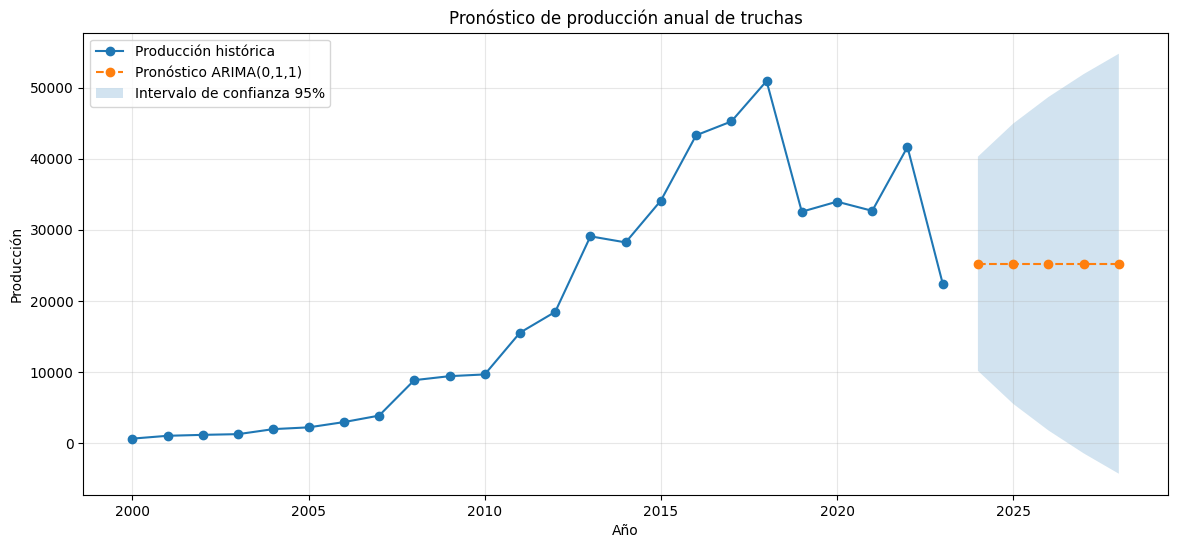

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["anios"],
    df["produccion"],
    marker="o",
    label="Producción histórica"
)

plt.plot(
    resultados_finales["Año"],
    resultados_finales["Producción pronosticada"],
    marker="o",
    linestyle="--",
    label="Pronóstico ARIMA(0,1,1)"
)

plt.fill_between(
    resultados_finales["Año"],
    resultados_finales["Limite inferior 95%"],
    resultados_finales["Limite superior 95%"],
    alpha=0.2,
    label="Intervalo de confianza 95%"
)

plt.title("Pronóstico de producción anual de truchas")
plt.xlabel("Año")
plt.ylabel("Producción")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

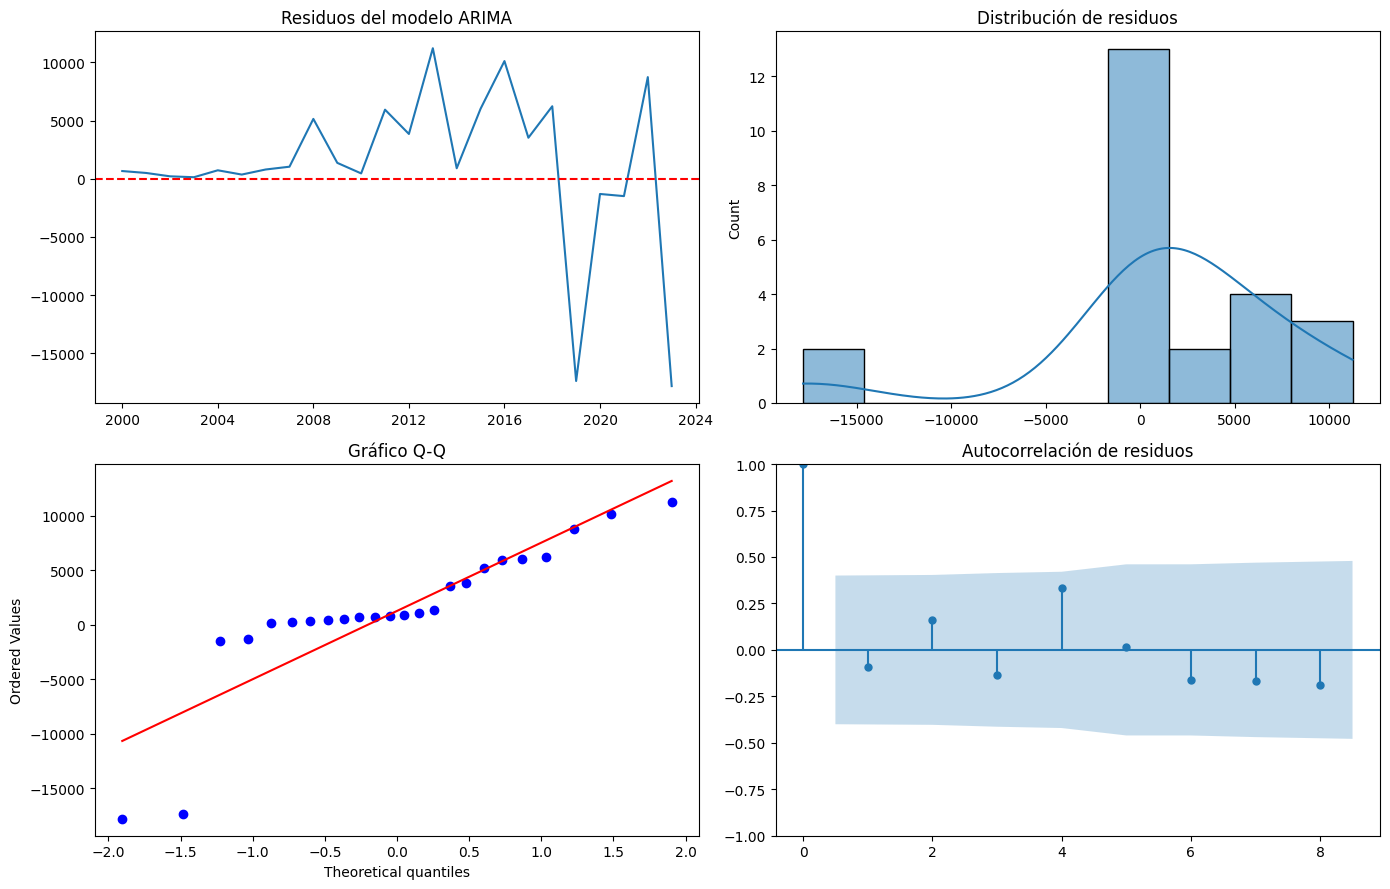

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.graphics.tsaplots import plot_acf
from scipy import stats

residuos = ajuste_final.resid

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Evolución de residuos
axes[0, 0].plot(residuos)
axes[0, 0].axhline(0, color="red", linestyle="--")
axes[0, 0].set_title("Residuos del modelo ARIMA")

# 2. Distribución
sns.histplot(
    residuos,
    kde=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Distribución de residuos")

# 3. Gráfico Q-Q
stats.probplot(
    residuos,
    dist="norm",
    plot=axes[1, 0]
)
axes[1, 0].set_title("Gráfico Q-Q")

# 4. Autocorrelación
plot_acf(
    residuos,
    lags=8,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Autocorrelación de residuos")

plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox

resultado_ljung = acorr_ljungbox(
    residuos,
    lags=[1, 3, 5],
    return_df=True,
    model_df=1
)

display(resultado_ljung)

,lb_stat,lb_pvalue
1,0.216959,NaN
3,1.499744,0.472427
5,4.940687,0.293438


In [ ]:
def modelo_arima_drift(train, horizonte):

    modelo = ARIMA(
        train,
        order=(0, 1, 1),
        trend="t"
    )

    ajuste = modelo.fit()

    return ajuste.forecast(steps=horizonte)


# Evaluar con la misma validación temporal
resultado_drift_arima = evaluar_modelo(
    "ARIMA(0,1,1) con Drift",
    modelo_arima_drift
)

display(pd.DataFrame([
    {
        "Modelo": "ARIMA(0,1,1)",
        "MAE": 6535.666408,
        "RMSE": 6775.308169,
        "MAPE": 18.866186
    },
    resultado_drift_arima
]))

,Modelo,MAE,RMSE,MAPE
0,"ARIMA(0,1,1)",6535.666408,6775.308169,18.866186
1,"ARIMA(0,1,1) con Drift",7094.719696,7822.750082,21.824314


In [ ]:
!pip install plotly -q

In [ ]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

from plotly.subplots import make_subplots

# ==========================================
# 1. PREPARAR INDICADORES
# ==========================================

produccion_2023 = float(serie.iloc[-1])

pronostico_2024 = float(
    resultados_finales.iloc[0]["Producción pronosticada"]
)

modelo_seleccionado = "ARIMA(0,1,1)"

rmse_modelo = 6775.308169

mape_modelo = 18.866186

# Variación porcentual
variacion_anual = serie.pct_change() * 100

# Residuos
residuos = ajuste_final.resid

# ==========================================
# 2. CREAR ESTRUCTURA DEL DASHBOARD
# ==========================================

fig = make_subplots(
    rows=4,
    cols=4,

    specs=[
        [{"type": "indicator"}, {"type": "indicator"},
         {"type": "indicator"}, {"type": "indicator"}],

        [{"type": "xy", "colspan": 2}, None,
         {"type": "xy", "colspan": 2}, None],

        [{"type": "xy", "colspan": 2}, None,
         {"type": "xy", "colspan": 2}, None],

        [{"type": "xy", "colspan": 2}, None,
         {"type": "xy", "colspan": 2}, None]
    ],

    subplot_titles=[
        "", "", "", "",
        "Producción histórica (2000-2023)",
        "Variación porcentual anual",
        "Comparación de modelos (RMSE)",
        "Pronóstico 2024-2028",
        "Distribución de residuos",
        "Optimización mediante Optuna"
    ],

    vertical_spacing=0.12,
    horizontal_spacing=0.10,
    row_heights=[0.7, 1.5, 1.5, 1.5]
)

# ==========================================
# 3. INDICADORES KPI
# ==========================================

kpis = [
    (produccion_2023, "Producción 2023"),
    (pronostico_2024, "Pronóstico 2024"),
    (rmse_modelo, "RMSE"),
    (mape_modelo, "MAPE (%)")
]

for i, (valor, titulo) in enumerate(kpis):

    fig.add_trace(
        go.Indicator(
            mode="number",
            value=valor,
            title={"text": titulo},
            number={"valueformat": ",.2f"}
        ),
        row=1,
        col=i+1
    )

# ==========================================
# 4. PRODUCCIÓN HISTÓRICA
# ==========================================

fig.add_trace(
    go.Scatter(
        x=serie.index.year,
        y=serie.values,
        mode="lines+markers",
        name="Producción histórica",
        line=dict(width=3)
    ),
    row=2,
    col=1
)

# ==========================================
# 5. VARIACIÓN ANUAL
# ==========================================

fig.add_trace(
    go.Bar(
        x=variacion_anual.index.year,
        y=variacion_anual.values,
        name="Variación anual (%)"
    ),
    row=2,
    col=3
)

# ==========================================
# 6. COMPARACIÓN DE MODELOS
# ==========================================

comparacion = tabla_resultados.copy()

# Agregar el modelo con deriva
comparacion = pd.concat([
    comparacion,
    pd.DataFrame([resultado_drift_arima])
], ignore_index=True)

fig.add_trace(
    go.Bar(
        x=comparacion["Modelo"],
        y=comparacion["RMSE"],
        name="RMSE por modelo",
        text=comparacion["RMSE"].round(2),
        textposition="outside"
    ),
    row=3,
    col=1
)

# ==========================================
# 7. PRONÓSTICO
# ==========================================

fig.add_trace(
    go.Scatter(
        x=serie.index.year,
        y=serie.values,
        mode="lines+markers",
        name="Histórico"
    ),
    row=3,
    col=3
)

fig.add_trace(
    go.Scatter(
        x=resultados_finales["Año"],
        y=resultados_finales["Limite superior 95%"],
        mode="lines",
        line=dict(width=0),
        showlegend=False,
        name="Límite superior"
    ),
    row=3,
    col=3
)

fig.add_trace(
    go.Scatter(
        x=resultados_finales["Año"],
        y=resultados_finales["Limite inferior 95%"],
        mode="lines",
        fill="tonexty",
        line=dict(width=0),
        name="Intervalo 95%",
        opacity=0.25
    ),
    row=3,
    col=3
)

fig.add_trace(
    go.Scatter(
        x=resultados_finales["Año"],
        y=resultados_finales["Producción pronosticada"],
        mode="lines+markers",
        name="Pronóstico ARIMA"
    ),
    row=3,
    col=3
)

# ==========================================
# 8. DISTRIBUCIÓN DE RESIDUOS
# ==========================================

fig.add_trace(
    go.Histogram(
        x=residuos,
        name="Residuos",
        nbinsx=10
    ),
    row=4,
    col=1
)

# ==========================================
# 9. HISTORIAL DE OPTUNA
# ==========================================

valores_optuna = [
    t.value for t in study.trials
    if t.value is not None and np.isfinite(t.value)
]

fig.add_trace(
    go.Scatter(
        x=list(range(1, len(valores_optuna)+1)),
        y=valores_optuna,
        mode="lines+markers",
        name="RMSE de Optuna"
    ),
    row=4,
    col=3
)

# ==========================================
# 10. CONFIGURACIÓN GENERAL
# ==========================================

fig.update_layout(
    title={
        "text": "MODELO UNIVARIANTE PARA PRONOSTICAR LA PRODUCCION ANUAL DE TRUCHAS EN LA CIUDAD DE PUNO",
        "x": 0.5,
        "xanchor": "center"
    },

    height=1500,
    template="plotly_white",
    showlegend=True,
    hovermode="x unified"
)

fig.update_xaxes(title_text="Año", row=2, col=1)
fig.update_yaxes(title_text="Producción", row=2, col=1)

fig.update_xaxes(title_text="Año", row=2, col=3)
fig.update_yaxes(title_text="Variación (%)", row=2, col=3)

fig.update_xaxes(title_text="Modelo", row=3, col=1)
fig.update_yaxes(title_text="RMSE", row=3, col=1)

fig.update_xaxes(title_text="Año", row=3, col=3)
fig.update_yaxes(title_text="Producción", row=3, col=3)

fig.update_xaxes(title_text="Residuo", row=4, col=1)
fig.update_yaxes(title_text="Frecuencia", row=4, col=1)

fig.update_xaxes(title_text="Número de prueba", row=4, col=3)
fig.update_yaxes(title_text="RMSE", row=4, col=3)

fig.show()

In [ ]:
from IPython.display import display, HTML
import pandas as pd
import numpy as np

# ==========================================
# 1. PREPARAR LOS RESULTADOS
# ==========================================

# Obtener los mejores modelos según RMSE
mejor = tabla_resultados.loc[
    tabla_resultados["RMSE"].idxmin()
]

naive = tabla_resultados[
    tabla_resultados["Modelo"] == "Naive"
].iloc[0]

# Resultados de Optuna
rmse_optuna = study.best_value
parametros_optuna = study.best_params

# Diferencia porcentual de RMSE frente a Naive
mejora_rmse = (
    (naive["RMSE"] - mejor["RMSE"])
    / naive["RMSE"]
) * 100

# Producción histórica
produccion_inicial = serie.iloc[0]
produccion_final = serie.iloc[-1]

crecimiento_total = (
    (produccion_final - produccion_inicial)
    / produccion_inicial
) * 100

# Producción pronosticada
promedio_pronostico = resultados_finales[
    "Producción pronosticada"
].mean()

# ==========================================
# 2. CONSTRUIR INTERPRETACIONES
# ==========================================

interpretacion_eda = f"""
La producción de truchas muestra un crecimiento importante a lo largo
del periodo analizado. En el año 2000 se registró una producción de
{produccion_inicial:,.2f}, mientras que en 2023 se alcanzaron
{produccion_final:,.2f}. Esto representa una variación acumulada
aproximada de {crecimiento_total:,.2f}%.

Sin embargo, el crecimiento no ha sido constante. Durante algunos años
se presentan disminuciones importantes, lo que demuestra que la
producción también está expuesta a fluctuaciones.
"""

interpretacion_modelo = f"""
Después de comparar los modelos Naive, Drift, Holt, ETS y diferentes
configuraciones ARIMA, se seleccionó {mejor['Modelo']} como candidato
principal, debido a que obtuvo el menor RMSE, con un valor de
{mejor['RMSE']:,.2f}.

Se eligió el RMSE como criterio principal porque penaliza con mayor
intensidad los errores de pronóstico elevados. No obstante, Naive
presentó un MAPE de {naive['MAPE']:.2f}%, ligeramente inferior al
MAPE de {mejor['MAPE']:.2f}% del modelo seleccionado.

La diferencia de RMSE frente a Naive es de aproximadamente
{mejora_rmse:.2f}%. Por ello, la ventaja predictiva de ARIMA es
moderada y debe interpretarse con cautela.
"""

interpretacion_optuna = f"""
Se utilizó Optuna para explorar diferentes combinaciones de
hiperparámetros del modelo ARIMA. La búsqueda identificó la
configuración p={parametros_optuna['p']}, d=1 y
q={parametros_optuna['q']}.

El RMSE obtenido fue {rmse_optuna:,.2f}, prácticamente igual al
resultado del modelo inicial ARIMA(0,1,1), cuyo RMSE fue 6,775.31.

Esto indica que la optimización confirmó la configuración inicial,
pero no consiguió una mejora adicional en el error de validación.
"""

interpretacion_pronostico = f"""
El modelo proyecta una producción promedio de
{promedio_pronostico:,.2f} para el periodo 2024-2028.

Los valores pronosticados se mantienen constantes porque el modelo
ARIMA(0,1,1) seleccionado no incorpora una deriva o tendencia
determinística. Esto no significa que la producción real vaya a
mantenerse necesariamente en ese nivel.

También se observa que los intervalos de confianza se amplían
conforme aumenta el horizonte de pronóstico, reflejando la
incertidumbre de las estimaciones futuras.
"""

interpretacion_residuos = """
El análisis de residuos permitió identificar que no existe evidencia
suficiente de autocorrelación residual en los rezagos 3 y 5, según
la prueba Ljung-Box.

Sin embargo, la prueba Jarque-Bera evidenció que los residuos no
presentan una distribución normal. Asimismo, el diagnóstico de
heterocedasticidad mostró que la varianza no es constante.

Estas condiciones indican que el modelo todavía presenta limitaciones
estadísticas. Por esta razón, sus pronósticos deben interpretarse
como estimaciones y no como valores futuros garantizados.
"""

# ==========================================
# 3. DISEÑO VISUAL DEL REPORTING
# ==========================================

html_interpretacion = f"""

<style>

.dashboard-report {{
    font-family: Arial, sans-serif;
    color: #243247;
    margin-top: 25px;
}}

.report-header {{
    background: #183B56;
    color: white;
    padding: 22px;
    border-radius: 12px;
    margin-bottom: 18px;
}}

.report-header h2 {{
    margin: 0;
    color: white;
}}

.report-header p {{
    margin-bottom: 0;
    color: #E3EDF5;
}}

.report-card {{
    background: #F7F9FC;
    border: 1px solid #E1E7EF;
    border-radius: 12px;
    padding: 18px;
    margin-bottom: 15px;
    line-height: 1.7;
}}

.report-card h3 {{
    color: #183B56;
    margin-top: 0;
}}

.report-card p {{
    margin-bottom: 0;
    text-align: justify;
}}

.report-note {{
    background: #FFF8E8;
    border-left: 5px solid #D99A24;
    padding: 17px;
    border-radius: 8px;
    margin-top: 15px;
    line-height: 1.7;
}}

.report-conclusion {{
    background: #EAF3F8;
    border-radius: 12px;
    padding: 20px;
    margin-top: 18px;
    line-height: 1.7;
}}

</style>

<div class="dashboard-report">

    <div class="report-header">
        <h2>Interpretación de los resultados</h2>
        <p>
        Producción anual de truchas | Periodo histórico 2000-2023
        | Proyección 2024-2028
        </p>
    </div>

    <div class="report-card">
        <h3>1. ¿Qué nos dicen los datos históricos?</h3>
        <p>{interpretacion_eda}</p>
    </div>

    <div class="report-card">
        <h3>2. ¿Por qué seleccionamos este modelo?</h3>
        <p>{interpretacion_modelo}</p>
    </div>

    <div class="report-card">
        <h3>3. ¿Qué conseguimos con Optuna?</h3>
        <p>{interpretacion_optuna}</p>
    </div>

    <div class="report-card">
        <h3>4. ¿Cómo debemos interpretar el pronóstico?</h3>
        <p>{interpretacion_pronostico}</p>
    </div>

    <div class="report-card">
        <h3>5. ¿Qué nos indica el análisis de residuos?</h3>
        <p>{interpretacion_residuos}</p>
    </div>

    <div class="report-conclusion">
        <h3>Conclusión general del análisis</h3>
        <p>
        El análisis permitió estudiar el comportamiento histórico
        de la producción anual de truchas, comparar diferentes
        alternativas de pronóstico y optimizar los parámetros
        mediante Optuna.

        Entre los modelos evaluados, ARIMA(0,1,1) obtuvo el menor
        RMSE y se mantuvo como la alternativa seleccionada bajo
        este criterio.

        </p>
    </div>

</div>
"""

# ==========================================
# 4. MOSTRAR DASHBOARD + INTERPRETACIONES
# ==========================================

from IPython.display import display, HTML

dashboard_completo = (
    fig.to_html(
        full_html=False,
        include_plotlyjs="cdn"
    )
    + html_interpretacion
)

display(HTML(dashboard_completo))

In [ ]:
# Exportar dashboard con gráficos e interpretaciones
html_final = fig.to_html(
    full_html=True,
    include_plotlyjs=True,
    config={"displayModeBar": True}
)

# Insertar las interpretaciones antes del cierre del body
html_final = html_final.replace(
    "</body>",
    html_interpretacion + "</body>"
)

with open(
    "Reporting_Truchas_Completo.html",
    "w",
    encoding="utf-8"
) as archivo:

    archivo.write(html_final)

from google.colab import files

files.download("Reporting_Truchas_Completo.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>